Sample covariance matrix:
 [[1.108 1.694]
 [1.694 3.806]]
Sample Pearson correlation: 0.824
Saved q2_scatter.png


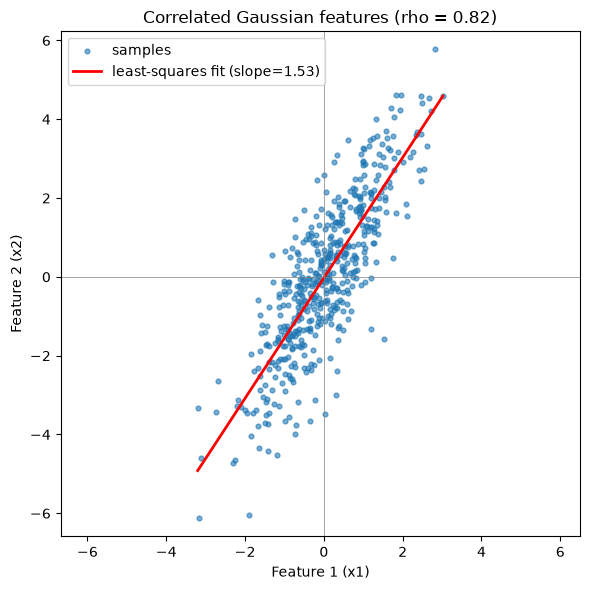

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 500

# Two correlated Gaussian features: specify mean vector and covariance matrix.
# Correlation rho = cov_xy / (sigma_x * sigma_y) = 1.6 / (1.0 * 2.0) = 0.8
mean = np.array([0.0, 0.0])
cov = np.array([[1.0, 1.6],
                [1.6, 4.0]])

X = rng.multivariate_normal(mean, cov, size=n)
x1, x2 = X[:, 0], X[:, 1]

# Empirical statistics
sample_cov = np.cov(X, rowvar=False)
rho = np.corrcoef(x1, x2)[0, 1]
print("Sample covariance matrix:\n", np.round(sample_cov, 3))
print(f"Sample Pearson correlation: {rho:.3f}")

# Line of best fit for the plot
slope, intercept = np.polyfit(x1, x2, 1)

# Scatter plot
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x1, x2, s=12, alpha=0.6, label="samples")
xs = np.linspace(x1.min(), x1.max(), 100)
ax.plot(xs, slope * xs + intercept, "r-", lw=2,
        label=f"least-squares fit (slope={slope:.2f})")
ax.set_xlabel("Feature 1 (x1)")
ax.set_ylabel("Feature 2 (x2)")
ax.set_title(f"Correlated Gaussian features (rho = {rho:.2f})")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
fig.tight_layout()
fig.savefig("q2_scatter.png", dpi=150)
print("Saved q2_scatter.png")
plt.show()

**Discussion Question no 2**
The dataset was generated by sampling 500 points from a 2D Gaussian with mean (0, 0) and covariance matrix Σ = [[1.0, 1.6], [1.6, 4.0]]. The diagonal entries set the variances of the two features (σ₁² = 1, σ₂² = 4, i.e. standard deviations 1 and 2), and the off-diagonal entry sets their covariance. The resulting correlation is ρ = 1.6 / (1 × 2) = 0.8, a strong positive correlation.

The scatter plot reflects each of these choices. The cloud is centered at the origin because of the zero mean. It extends roughly ±3 along x1 but ±6 along x2, since x2 has twice the standard deviation. Most importantly, the cloud forms an elongated ellipse tilted upward rather than an upright one: points with large positive x1 tend to have large positive x2, and vice versa, so the upper-right and lower-left quadrants are densely populated while the upper-left and lower-right are nearly empty. This tilt is the visual signature of correlation; with zero covariance the ellipse would be aligned with the axes, and with negative covariance it would tilt downward.

Mean vector mu: [0.036 0.029]
Mean after centering: [-0.  0.]

Covariance matrix Sigma:
 [[1.108 1.694]
 [1.694 3.806]]
Check against np.cov: True

Eigenvalues (descending): [4.623 0.292]
Eigenvectors (columns = PC1, PC2):
 [[ 0.434 -0.901]
 [ 0.901  0.434]]

Variance of projected data: [4.623 0.292]
(should equal the eigenvalues)


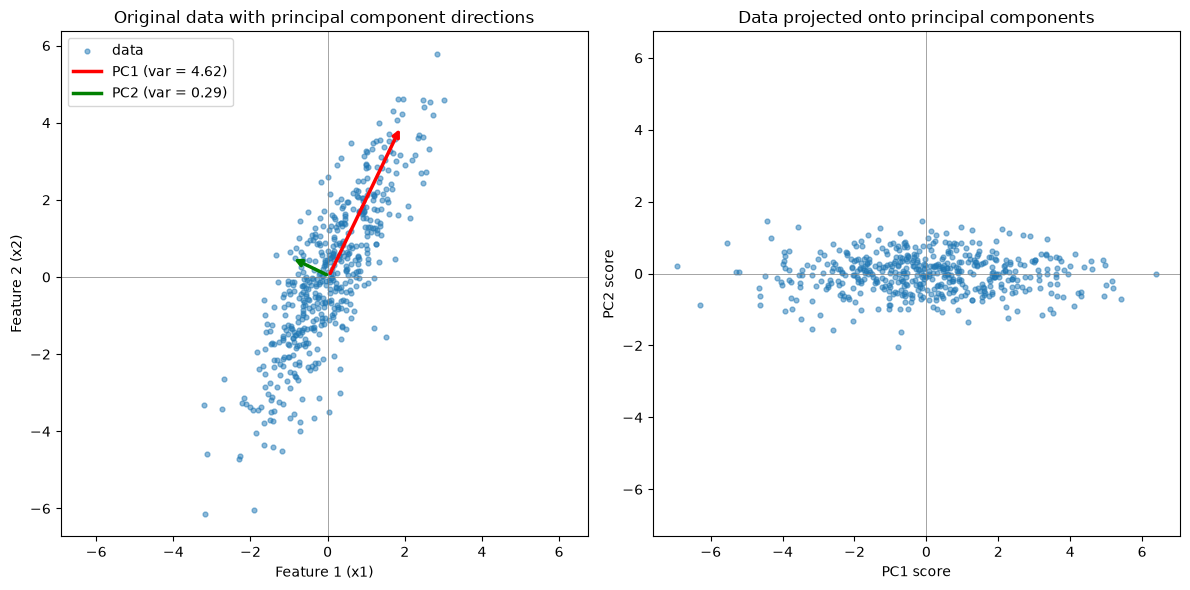

In [2]:
# ---------- Q3: PCA from scratch ----------

# Step 1: Center the data (mean subtraction)
# From Q1: Sigma = E[(X - mu)(X - mu)^T]. Centering makes mu = 0, so
# the covariance is just E[X_c X_c^T].
mu = X.mean(axis=0)            # mean of each feature, shape (2,)
X_c = X - mu                   # centered data, shape (n, 2)
print("Mean vector mu:", np.round(mu, 3))
print("Mean after centering:", np.round(X_c.mean(axis=0), 10))

# Step 2: Covariance matrix
# Sigma = (1/(n-1)) * X_c^T X_c  -- the sample version of E[X_c X_c^T]
Sigma = (X_c.T @ X_c) / (n - 1)
print("\nCovariance matrix Sigma:\n", np.round(Sigma, 3))
print("Check against np.cov:", np.allclose(Sigma, np.cov(X_c, rowvar=False)))

# Step 3: Eigen-decomposition
# From Q1: Var(u^T X) = u^T Sigma u. Maximizing this subject to ||u|| = 1
# gives Sigma u = lambda u. So eigenvectors = directions of max variance,
# eigenvalues = the variance along each of those directions.
# eigh is used because Sigma is symmetric (returns real values, sorted ascending).
eigvals, eigvecs = np.linalg.eigh(Sigma)

# Step 4: Sort by eigenvalue, descending, and pick principal components
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]    # column i is the i-th principal component
print("\nEigenvalues (descending):", np.round(eigvals, 3))
print("Eigenvectors (columns = PC1, PC2):\n", np.round(eigvecs, 3))

pc1 = eigvecs[:, 0]
pc2 = eigvecs[:, 1]

# Projection onto the principal components (used in Q4)
Z = X_c @ eigvecs              # scores, shape (n, 2)
print("\nVariance of projected data:", np.round(Z.var(axis=0, ddof=1), 3))
print("(should equal the eigenvalues)")

# ---------- Visualization ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Left: original data with PC directions drawn from the mean
ax = axes[0]
ax.scatter(X[:, 0], X[:, 1], s=12, alpha=0.5, label="data")
for i, (vec, val, col) in enumerate(zip([pc1, pc2], eigvals, ["red", "green"])):
    # arrow length = 2 standard deviations along that component
    length = 2 * np.sqrt(val)
    ax.annotate("", xy=mu + length * vec, xytext=mu,
                arrowprops=dict(arrowstyle="->", color=col, lw=2.5))
    ax.plot([], [], color=col, lw=2.5, label=f"PC{i+1} (var = {val:.2f})")
ax.set_xlabel("Feature 1 (x1)"); ax.set_ylabel("Feature 2 (x2)")
ax.set_title("Original data with principal component directions")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_aspect("equal", adjustable="datalim")
ax.legend()

# Right: data expressed in the PC coordinate system (rotated)
ax = axes[1]
ax.scatter(Z[:, 0], Z[:, 1], s=12, alpha=0.5)
ax.set_xlabel("PC1 score"); ax.set_ylabel("PC2 score")
ax.set_title("Data projected onto principal components")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_aspect("equal", adjustable="datalim")

fig.tight_layout()
fig.savefig("q3_pca.png", dpi=150)
plt.show()

Q3: PCA from scratch — implementation linked to the Q1 derivation

In Q1 we showed that for a unit vector $u$, the variance of the projection $u^T X$ is

$$\text{Var}(u^T X) = u^T \Sigma u, \qquad \Sigma = E\big[(X-\mu)(X-\mu)^T\big].$$

PCA finds the $u$ that maximizes this variance. The implementation below follows that derivation step by step.

Step 1 — Centering (mean subtraction).
$\Sigma$ is defined in terms of $(X - \mu)$. We estimate $\mu$ by the sample mean and subtract it from every sample: X_c = X - mu. The centered data has zero mean, so the $(X-\mu)$ term simply becomes $X_c$.

Step 2 — Covariance matrix.
The expectation $E[\cdot]$ becomes an average over the $n$ samples. With samples as rows of $X_c$,

$$\Sigma \approx \frac{1}{n-1} X_c^T X_c,$$

computed directly as Sigma = (X_c.T @ X_c) / (n - 1). This is the $\Sigma$ that appears in $u^T \Sigma u$. (We check it against np.cov for correctness.)

Step 3 — Eigenvalues and eigenvectors.
To maximize $u^T \Sigma u$ subject to $\|u\| = 1$, form the Lagrangian $\mathcal{L} = u^T \Sigma u - \lambda(u^T u - 1)$. Setting $\partial \mathcal{L}/\partial u = 0$ gives

$$\Sigma u = \lambda u,$$

so the optimal direction is an eigenvector of $\Sigma$, and the variance along it is $u^T \Sigma u = u^T(\lambda u) = \lambda$, its eigenvalue. The line np.linalg.eigh(Sigma) solves exactly this equation; eigh is used because $\Sigma$ is symmetric, which guarantees real eigenvalues and orthogonal eigenvectors.

Step 4 — Selecting principal components.
Since variance along each eigenvector equals its eigenvalue, the direction of maximum variance is the eigenvector with the largest $\lambda$. We sort eigenvalues in descending order and reorder the eigenvector columns to match. Column 0 is PC1, column 1 is PC2. Projecting the centered data onto these directions, $Z = X_c V$, gives the data in PC coordinates; the variance of each column of $Z$ equals the corresponding eigenvalue, which verifies the derivation numerically.

Total variance (trace of Sigma): 4.915
PC1: eigenvalue = 4.623, explained = 94.1%, cumulative = 94.1%
PC2: eigenvalue = 0.292, explained = 5.9%, cumulative = 100.0%

Reconstruction error using 1 PC: 0.292
(equals the discarded eigenvalue lambda_2 = 0.292)


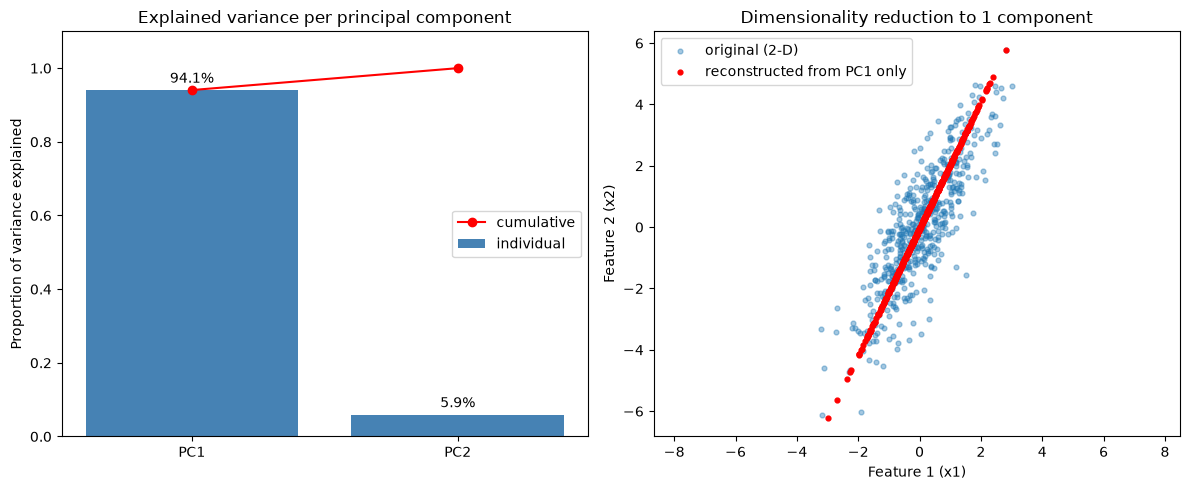

In [3]:
# ---------- Q4: Explained variance ----------

# Step 1: proportion of total variance explained by each PC
total_var = eigvals.sum()                 # = trace(Sigma)
explained_ratio = eigvals / total_var
cumulative = np.cumsum(explained_ratio)

print("Total variance (trace of Sigma):", round(total_var, 3))
for i, (lam, r, c) in enumerate(zip(eigvals, explained_ratio, cumulative)):
    print(f"PC{i+1}: eigenvalue = {lam:.3f}, explained = {r:.1%}, cumulative = {c:.1%}")

# Step 2: reduce to 1 dimension (keep PC1 only) and reconstruct
k = 1
V_k = eigvecs[:, :k]                       # keep first k components
Z_k = X_c @ V_k                            # (n, k) reduced representation
X_recon = Z_k @ V_k.T + mu                 # map back to 2D
recon_error = np.mean(np.sum((X - X_recon) ** 2, axis=1))
print(f"\nReconstruction error using {k} PC: {recon_error:.3f}")
print(f"(equals the discarded eigenvalue lambda_2 = {eigvals[1]:.3f})")

# Step 3: plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scree plot
ax = axes[0]
labels = [f"PC{i+1}" for i in range(len(eigvals))]
ax.bar(labels, explained_ratio, color="steelblue", label="individual")
ax.plot(labels, cumulative, "ro-", label="cumulative")
for i, r in enumerate(explained_ratio):
    ax.text(i, r + 0.02, f"{r:.1%}", ha="center")
ax.set_ylim(0, 1.1)
ax.set_ylabel("Proportion of variance explained")
ax.set_title("Explained variance per principal component")
ax.legend()

# Original vs 1-D reconstruction
ax = axes[1]
ax.scatter(X[:, 0], X[:, 1], s=12, alpha=0.4, label="original (2-D)")
ax.scatter(X_recon[:, 0], X_recon[:, 1], s=12, color="red",
           label="reconstructed from PC1 only")
ax.set_xlabel("Feature 1 (x1)"); ax.set_ylabel("Feature 2 (x2)")
ax.set_title("Dimensionality reduction to 1 component")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()

fig.tight_layout()
fig.savefig("q4_explained_variance.png", dpi=150)
plt.show()

Q4: Explained variance and dimensionality reduction

Computation. Since the variance along principal component $i$ equals its eigenvalue $\lambda_i$, and the eigenvectors are orthogonal, the total variance of the data is $\sum_i \lambda_i = \text{trace}(\Sigma)$. The proportion of variance explained by PC$_i$ is therefore

$$\text{EVR}_i = \frac{\lambda_i}{\sum_j \lambda_j}.$$

For our data, $\lambda_1 \approx 4.62$ and $\lambda_2 \approx 0.29$, giving a total of $4.91$ (the trace of $\Sigma$, $1.108 + 3.806$). PC1 explains about 94% of the variance and PC2 about 6%.

Interpretation. The two original features are strongly correlated ($\rho \approx 0.8$), so they carry largely redundant information. PCA rotates to a coordinate system where one direction (PC1, along the long axis of the ellipse) captures almost everything, and the orthogonal direction (PC2) captures only the small residual scatter around that axis. The scree plot makes this visible: a steep drop from PC1 to PC2.

Dimensionality reduction. Keeping only PC1 reduces each sample from 2 numbers to 1 — a 50% reduction in dimensionality — while retaining 94% of the variance. Reconstructing the data from PC1 alone projects every point onto the PC1 line (red points in the right plot). The mean squared reconstruction error equals the discarded eigenvalue, $\lambda_2 \approx 0.29$: the variance we throw away is exactly the information we lose. This is why PCA is optimal among linear projections — for any choice of $k$, it minimizes reconstruction error by keeping the $k$ largest eigenvalues.

The trade-off. Fewer dimensions mean lower storage, faster downstream algorithms, less noise, and easier visualization, but every dropped component loses some variance. The explained-variance ratio quantifies this: each retained PC adds $\lambda_i / \sum_j \lambda_j$ to the cumulative total, and components are added in order of diminishing returns. In practice one picks the smallest $k$ whose cumulative explained variance crosses a threshold (commonly 90–95%), or looks for the "elbow" in the scree plot. Here $k = 1$ clears 94%, so one component is a good choice. If the features had been uncorrelated with equal variance, both eigenvalues would be equal, each PC would explain 50%, and dropping one would lose half the information — PCA is only effective when the data has a dominant direction of variation, which correlation creates.

One caveat worth noting: explained variance is not the same as usefulness for a task. A low-variance direction can still carry the signal that matters for a classifier, so the variance threshold is a heuristic, not a guarantee.